# Описание проекта

Вы работаете в фотохостинге для профессиональных фотографов «Со Смыслом» (“With Sense”). 
Ваши пользователи размещают свои фотографии на хостинге и сопровождают их полным описанием: указывают место съёмок, модель камеры и т. д. Отличительная особенность сервиса — описание: его может предоставить не только тот, кто размещает фотографию, но и другие пользователи портала. 

Например, для этой фотографии:

![Заменяющий текст](https://pictures.s3.yandex.net/resources/54501196_a9ac9d66f2_1661350725.jpg)

описание выглядит так:

*⎢ A hiker poses for a picture in front of stunning mountains and clouds.*

Ваш отдел занимается экспериментом по разработке поиска референсных фотографий для фотографов. Суть поиска заключается в следующем: пользователь сервиса вводит описание нужной сцены. Например, такое:

*⎢ A man is crossing a mountain pass on a metal bridge.*

Сервис выводит несколько фотографий с такой же или похожей сценой.


![Заменяющий текст](https://pictures.s3.yandex.net/resources/551403320_dfdcf9fc3b_1661350763.jpg)

# Юридические ограничения

В некоторых странах, где работает компания With Sense, действуют ограничения по обработке изображений: поисковым сервисам и сервисам, предоставляющим возможность поиска, запрещено без разрешения родителей или законных представителей предоставлять любую информацию, в том числе, но не исключительно, текстов, изображений, видео и аудио, содержащие описание, изображение или запись голоса детей. Ребёнком считается любой человек, не достигший 16-ти лет.

В вашем сервисе строго следуют законам стран, в которых работают. Поэтому при попытке посмотреть изображения, запрещённые законодательством, вместо картинок показывается дисклеймер:

*⎢ This image is unavailable in your country in compliance with local laws.*

Однако у вас в PoC нет возможности воспользоваться данным функционалом. Поэтому необходимо очистить данные от проблемного контента. Во время тестирования модели при появлении в запросе “вредного” контента должен отображаться дисклеймер. 

# Описание данных

Данные представлены в пяти таблицах и двух папках с фотографиями. Одна строка обучающей таблицы соответствует паре «изображение — текстовое описание». Для этих пар доступны экспертные и краудсорсинговые оценки соответствия.

**Таблица `train_dataset.csv` — пары изображений и описаний для обучения, 5822 строки.**

| Столбец | Описание | Тип данных |
| :--- | :--- | :--- |
| `image` | Имя файла изображения, с которым сравнивается описание | Строка |
| `query_id` | Идентификатор текстового описания | Строка |
| `query_text` | Текст описания на английском языке | Строка |

Идентификатор `query_id` имеет формат `<имя файла изображения>#<номер описания>`. Имя файла внутри него указывает на исходную фотографию описания. Она может отличаться от фотографии в столбце `image`: в данных есть как соответствующие, так и несоответствующие пары.

**Таблица `ExpertAnnotations.tsv` — экспертные оценки соответствия, 5822 строки.**

| Столбец | Описание | Тип данных |
| :--- | :--- | :--- |
| `image` | Имя файла изображения | Строка |
| `query_id` | Идентификатор описания | Строка |
| `expert_1` | Оценка первого эксперта | Целое число от 1 до 4 |
| `expert_2` | Оценка второго эксперта | Целое число от 1 до 4 |
| `expert_3` | Оценка третьего эксперта | Целое число от 1 до 4 |

Эксперты оценивают соответствие изображения описанию по следующей шкале:

- **1** — изображение и описание совершенно не соответствуют друг другу;
- **2** — совпадают отдельные элементы, но в целом описание не соответствует изображению;
- **3** — изображение и описание соответствуют друг другу с расхождениями в некоторых деталях;
- **4** — изображение и описание полностью соответствуют друг другу.

**Таблица `CrowdAnnotations.tsv` — краудсорсинговые оценки соответствия, 47 830 строк.**

| Столбец | Описание | Тип данных |
| :--- | :--- | :--- |
| `image` | Имя файла изображения | Строка |
| `query_id` | Идентификатор описания | Строка |
| `crowd_share` | Доля исполнителей, подтвердивших соответствие изображения описанию | Вещественное число от 0 до 1 |
| `votes_match` | Количество голосов за соответствие | Целое число |
| `votes_mismatch` | Количество голосов против соответствия | Целое число |

В исходных файлах `ExpertAnnotations.tsv` и `CrowdAnnotations.tsv` нет заголовков. Названия столбцов задаются при загрузке. Разметка относится к конкретной паре, поэтому для соединения таблиц используются два поля: `image` и `query_id`.

**Таблица `test_queries.csv` — текстовые запросы для тестирования поиска, 500 строк.**

| Столбец | Описание | Тип данных |
| :--- | :--- | :--- |
| `query_id` | Идентификатор тестового описания | Строка |
| `query_text` | Текст запроса на английском языке | Строка |
| `image` | Имя исходной фотографии, которой соответствует описание | Строка |

Первая колонка файла содержит сохранённый индекс строк и при загрузке используется как индекс таблицы. Экспертных оценок в этом файле нет.

**Таблица `test_images.csv` — список фотографий для тестовой поисковой галереи, 100 строк.**

| Столбец | Описание | Тип данных |
| :--- | :--- | :--- |
| `image` | Имя файла тестового изображения | Строка |

**Папки с изображениями:**

- `train_images` — 1000 фотографий обучающего набора;
- `test_images` — 100 фотографий для внешнего тестирования поиска.

Обучающие пары используются для исследования данных, обучения и валидации моделей. Внешние тестовые фотографии и запросы используются для демонстрации поиска выбранной модели.

# Для ревьюера
<div style='border:solid orange 2px; padding: 20px'>
Работал локально на apple m4 (mps), взял LinReg, BERT, ResNet50, полносвязку и CLIP. Предобученные ResNet50, BERT и кодировщики CLIP использовал без дообучения. На их признаках обучил линейную регрессию и полносвязные сети. Весь проект выполняется (на air m4) за 116 сек.

Версия Python: `3.14.6`.

Основные библиотеки:

| Библиотека | Версия |
|---|---|
| NumPy | 2.4.6 |
| pandas | 3.0.3 |
| Matplotlib | 3.11.1 |
| Seaborn | 0.13.2 |
| Pillow | 12.3.0 |
| tqdm | 4.69.0 |
| PyTorch | 2.14.0 |
| torchvision | 0.29.0 |
| Transformers | 5.17.0 |
| scikit-learn | 1.9.0 |

При запуске в другом окружении необходимо изменить пути `DATA_DIR` и `FEATURES_DIR`.

# 1. Загрузка и первичный просмотр

Сперва загрузим таблицы и посмотрим размеры, типы столбцов и несколько строк.

In [1]:
# Ячейка импортов, констант и настроек

# Импорты
import os
from pathlib import Path
from copy import deepcopy
from textwrap import fill
import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from PIL import Image
from tqdm.auto import tqdm
import torch
from torch import nn
from torchvision.models import resnet50, ResNet50_Weights
from transformers import AutoTokenizer, AutoModel, AutoProcessor, CLIPModel
from sklearn import set_config
from sklearn.base import BaseEstimator, RegressorMixin
from sklearn.model_selection import GroupShuffleSplit
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error

# Константы
DATA_DIR = Path('/Users/mac/Programming/Jupyter/datasets/to_upload')
FEATURES_DIR = Path('/Users/mac/Programming/Jupyter/datasets/features')
TRAIN_IMAGES_DIR = DATA_DIR / 'train_images'
TEST_IMAGES_DIR = DATA_DIR / 'test_images'
RANDOM_STATE = 42
PALETTE = sns.color_palette('Set2')
DEVICE = torch.device(
    'cuda' if torch.cuda.is_available()
    else 'mps' if torch.backends.mps.is_available() else 'cpu'
)

# Настройки
torch.manual_seed(RANDOM_STATE)
torch.set_num_threads(4)
os.environ['HF_DEACTIVATE_ASYNC_LOAD'] = '1'
set_config(enable_metadata_routing=True)
pd.set_option('display.float_format', '{:.4f}'.format)
sns.set_theme(style='whitegrid')

Сперва загрузим данные, после проведем первичный осмотр.

In [2]:
train_df = pd.read_csv(DATA_DIR / 'train_dataset.csv')

In [3]:
expert_df = pd.read_csv(
    DATA_DIR / 'ExpertAnnotations.tsv',
    sep='\t',
    header=None,
    names=['image', 'query_id', 'expert_1', 'expert_2', 'expert_3']
)

In [4]:
crowd_df = pd.read_csv(
    DATA_DIR / 'CrowdAnnotations.tsv',
    sep='\t',
    header=None,
    names=['image', 'query_id', 'crowd_share', 'votes_match', 'votes_mismatch']
)

In [5]:
test_queries_df = pd.read_csv(
    DATA_DIR / 'test_queries.csv',
    sep='|',
    index_col=0
)

In [6]:
test_images_df = pd.read_csv(DATA_DIR / 'test_images.csv')

Создадим словарь с нашими датасетами. Проведем первичный осмотр.

In [7]:
tables = {
    'train': train_df,
    'expert': expert_df,
    'crowd': crowd_df,
    'test_queries': test_queries_df,
    'test_images': test_images_df
}

In [8]:
for name, df in tables.items():
    print(f'__________{name}__________')
    df.info()
    display(df.sample(2, random_state=RANDOM_STATE))

__________train__________
<class 'pandas.DataFrame'>
RangeIndex: 5822 entries, 0 to 5821
Data columns (total 3 columns):
 #   Column      Non-Null Count  Dtype
---  ------      --------------  -----
 0   image       5822 non-null   str  
 1   query_id    5822 non-null   str  
 2   query_text  5822 non-null   str  
dtypes: str(3)
memory usage: 136.6 KB


,image,query_id,query_text
544,542317719_ed4dd95dc2.jpg,3591458156_f1a9a33918.jpg#2,A man at a rodeo is thrown off a horse .
1894,3301811927_a2797339e5.jpg,3301811927_a2797339e5.jpg#2,Hockey players with one taking a shot .


__________expert__________
<class 'pandas.DataFrame'>
RangeIndex: 5822 entries, 0 to 5821
Data columns (total 5 columns):
 #   Column    Non-Null Count  Dtype
---  ------    --------------  -----
 0   image     5822 non-null   str  
 1   query_id  5822 non-null   str  
 2   expert_1  5822 non-null   int64
 3   expert_2  5822 non-null   int64
 4   expert_3  5822 non-null   int64
dtypes: int64(3), str(2)
memory usage: 227.6 KB


,image,query_id,expert_1,expert_2,expert_3
544,172097782_f0844ec317.jpg,3641022607_e7a5455d6c.jpg#2,3,4,4
1894,2621415349_ef1a7e73be.jpg,2675685200_0913d84d9b.jpg#2,1,1,2


__________crowd__________
<class 'pandas.DataFrame'>
RangeIndex: 47830 entries, 0 to 47829
Data columns (total 5 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   image           47830 non-null  str    
 1   query_id        47830 non-null  str    
 2   crowd_share     47830 non-null  float64
 3   votes_match     47830 non-null  int64  
 4   votes_mismatch  47830 non-null  int64  
dtypes: float64(1), int64(2), str(2)
memory usage: 1.8 MB


,image,query_id,crowd_share,votes_match,votes_mismatch
46396,700884207_d3ec546494.jpg,2450299735_62c095f40e.jpg#2,0.0000,0,3
13591,2533424347_cf2f84872b.jpg,3310067561_b92017acab.jpg#2,0.0000,0,3


__________test_queries__________
<class 'pandas.DataFrame'>
RangeIndex: 500 entries, 0 to 499
Data columns (total 3 columns):
 #   Column      Non-Null Count  Dtype
---  ------      --------------  -----
 0   query_id    500 non-null    str  
 1   query_text  500 non-null    str  
 2   image       500 non-null    str  
dtypes: str(3)
memory usage: 11.8 KB


,query_id,query_text,image
361,3482859574_3908de3427.jpg#1,A group of girls who are gothically dressed st...,3482859574_3908de3427.jpg
73,2141713971_e25eb12712.jpg#3,A woman and girl riding downhill on a sled wit...,2141713971_e25eb12712.jpg


__________test_images__________
<class 'pandas.DataFrame'>
RangeIndex: 100 entries, 0 to 99
Data columns (total 1 columns):
 #   Column  Non-Null Count  Dtype
---  ------  --------------  -----
 0   image   100 non-null    str  
dtypes: str(1)
memory usage: 932.0 bytes


,image
83,2505056124_1276e8dbcb.jpg
53,3553476195_fb3747d7c1.jpg


In [9]:
pd.DataFrame({name: [len(df), df['image'].nunique(), df.isna().sum().sum()] 
              for name, df in tables.items()
             }, index=['Строк', 'Фотографий', 'Пропусков']).T

,Строк,Фотографий,Пропусков
train,5822,1000,0
expert,5822,1000,0
crowd,47830,1000,0
test_queries,500,100,0
test_images,100,100,0


**Вывод по загрузке.**

Данные загружены. В обучающей таблице 5822 пары, 1000 фотографий и 977 описаний. Внешний тест содержит 500 описаний для 100 фотографий. Пропусков в исходных таблицах нет, типы столбцов соответствуют содержимому. Экспертная разметка дана по шкале 1-4, краудсорсинговая - как доля положительных голосов и их количество.

# 2. Предобработка

Проверим дубликаты, объединим обучающие пары с экспертными оценками и создадим таргет.

In [10]:
for name, df in tables.items():
    print(name, '- полных дубликатов:', df.duplicated().sum())

train - полных дубликатов: 0
expert - полных дубликатов: 0
crowd - полных дубликатов: 0
test_queries - полных дубликатов: 0
test_images - полных дубликатов: 0


In [11]:
train_df.duplicated(['image', 'query_id']).sum()

np.int64(0)

In [12]:
expert_df.duplicated(['image', 'query_id']).sum()

np.int64(0)

Объеденим тренеровочный датасет и оценку экспертов и получится датасет с признаками и таргетом(создадим из оценки трех экспертов).

In [13]:
model_df = train_df.merge(expert_df, on=['image', 'query_id'], 
                          how='left', validate='one_to_one')

In [14]:
model_df.info()

<class 'pandas.DataFrame'>
RangeIndex: 5822 entries, 0 to 5821
Data columns (total 6 columns):
 #   Column      Non-Null Count  Dtype
---  ------      --------------  -----
 0   image       5822 non-null   str  
 1   query_id    5822 non-null   str  
 2   query_text  5822 non-null   str  
 3   expert_1    5822 non-null   int64
 4   expert_2    5822 non-null   int64
 5   expert_3    5822 non-null   int64
dtypes: int64(3), str(3)
memory usage: 273.0 KB


Отлично, повторяющихся пар небыло, т.к. у нас была бы ошибка, ведь у нас стоит one_to_one. 

In [15]:
model_df.sample(5, random_state=RANDOM_STATE)

,image,query_id,query_text,expert_1,expert_2,expert_3
544,542317719_ed4dd95dc2.jpg,3591458156_f1a9a33918.jpg#2,A man at a rodeo is thrown off a horse .,1,1,1
1894,3301811927_a2797339e5.jpg,3301811927_a2797339e5.jpg#2,Hockey players with one taking a shot .,4,4,4
5546,3516825206_5750824874.jpg,2944362789_aebbc22db4.jpg#2,A skateboarder is skating down a very steep ra...,1,1,1
4923,2498897831_0bbb5d5b51.jpg,3677318686_b018862bb7.jpg#2,A little boy in a purple shirt and blue shorts...,1,1,1
3624,2358561039_e215a8d6cd.jpg,1287073593_f3d2a62455.jpg#2,Dogs pulling a sled in a sled race .,4,4,4


Пары соединяем по `image + query_id`: одно описание сопоставляется с разными фотографиями, поэтому одного имени файла для объединения недостаточно.

Возьмём среднее трёх экспертных оценок и перенесём шкалу `[1, 4]` в `[0, 1]`. Так сохраним промежуточные степени соответствия. В прекоде разрешено выбирать свой способ агрегации. Полученное число будем называть оценкой соответствия.

In [16]:
model_df['target'] = ((model_df[['expert_1', 'expert_2', 'expert_3']]
    .mean(axis=1) - 1) / 3)

In [17]:
model_df[['expert_1', 'expert_2', 'expert_3', 'target']].describe().T

,count,mean,std,min,25%,50%,75%,max
expert_1,5822.0000,1.4366,0.7871,1.0000,1.0000,1.0000,2.0000,4.0000
expert_2,5822.0000,1.6244,0.8562,1.0000,1.0000,1.0000,2.0000,4.0000
expert_3,5822.0000,1.8820,0.9041,1.0000,1.0000,2.0000,2.0000,4.0000
target,5822.0000,0.2159,0.2687,0.0000,0.0000,0.1111,0.3333,1.0000


Отлично, минимальные и максимальные значения корректны.

## Ограниченный контент

Составим список слов, которые могут указывать на детей. Ищем отдельные слова без учёта регистра. `young` и `little` отдельно не используем: они встречаются и в описаниях взрослых или животных.

In [18]:
BLOCK_WORDS = [
    'baby', 'babies', 'infant', 'infants', 'toddler', 'toddlers',
    'child', 'children', 'kid', 'kids',
    'boy', 'boys', 'girl', 'girls',
    'teen', 'teens', 'teenage', 'teenager', 'teenagers',
    'youth', 'youths',
    'schoolboy', 'schoolboys', 'schoolgirl', 'schoolgirls',
    'schoolchild', 'schoolchildren', 'newborn', 'newborns'
]

In [19]:
BLOCK_PATTERN = r'\b(?:' + '|'.join(BLOCK_WORDS) + r')\b'

In [20]:
blocked_text_mask = model_df['query_text'].str.contains(BLOCK_PATTERN, 
                                                        case=False, regex=True)

In [21]:
blocked_images = set(model_df.loc[blocked_text_mask, 
    'query_id'].str.split('#').str[0])

In [22]:
len(blocked_images)

292

Часть `query_id` до `#` указывает на исходную фотографию описания. Исключим
как проблемные описания, так и все пары с выявленными фотографиями.

In [23]:
blocked_pair_mask = (blocked_text_mask | model_df['image'].isin(blocked_images))

In [24]:
clean_df = model_df.loc[~blocked_pair_mask].copy().reset_index(drop=True)

In [25]:
clean_df.info()

<class 'pandas.DataFrame'>
RangeIndex: 3162 entries, 0 to 3161
Data columns (total 7 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   image       3162 non-null   str    
 1   query_id    3162 non-null   str    
 2   query_text  3162 non-null   str    
 3   expert_1    3162 non-null   int64  
 4   expert_2    3162 non-null   int64  
 5   expert_3    3162 non-null   int64  
 6   target      3162 non-null   float64
dtypes: float64(1), int64(3), str(3)
memory usage: 173.1 KB


In [26]:
pd.DataFrame({
    'До фильтрации': [len(model_df), model_df['image'].nunique(), 
                      model_df['query_id'].nunique()],
    'После фильтрации': [len(clean_df), clean_df['image'].nunique(), 
                         clean_df['query_id'].nunique()]
}, index=['Пар', 'Фотографий', 'Описаний'])

,До фильтрации,После фильтрации
Пар,5822,3162
Фотографий,1000,703
Описаний,977,665


In [27]:
blocked_examples = (
    model_df.loc[blocked_text_mask, ['query_id', 'query_text']]
    .drop_duplicates(subset='query_id')
    .sample(4, random_state=RANDOM_STATE)
)

Посмотрим то, что мы убрали фильтром.

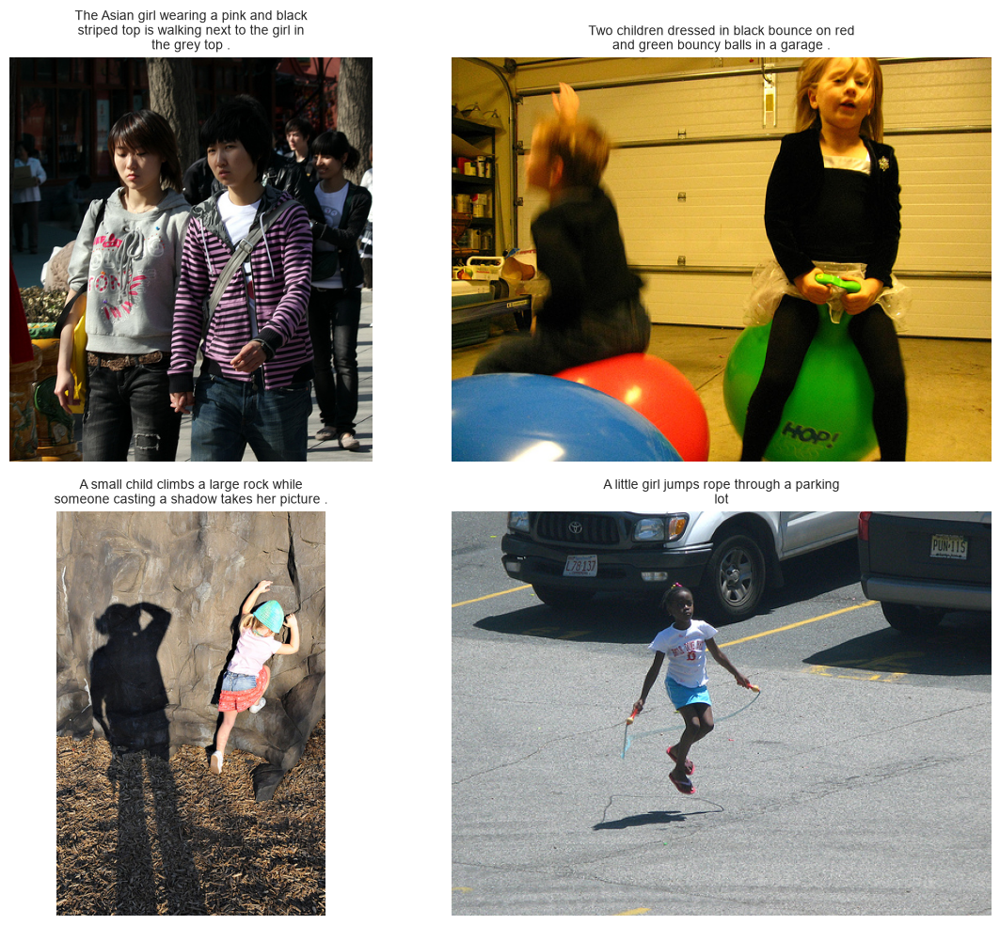

In [28]:
fig, axes = plt.subplots(2, 2, figsize=(12, 10))

for ax, (_, row) in zip(axes.flat, blocked_examples.iterrows()):
    image_name = row['query_id'].split('#')[0]

    with Image.open(TRAIN_IMAGES_DIR / image_name) as image:
        ax.imshow(image)

    ax.set_title(fill(row['query_text'], width=45), fontsize=10)
    ax.axis('off')

plt.tight_layout()
plt.show()

**Вывод по предобработке.**

Полных дубликатов и повторяющихся ключей обучающих пар не обнаружено. После объединения для всех 5822 пар доступны три экспертные оценки. Создали таргет в диапазоне `[0, 1]`.

По словарю выявлены 292 исходные фотографии. После исключения связанных пар остались 3162 пары, 703 фотографии и 665 описаний. Словарный фильтр приблизителен: он зависит от формулировок, а слово `girl` может относиться и ко взрослому человеку.

# 3. Исследовательский анализ данных

Изучим распределение оценок, согласованность экспертов и длины описаний.
Сначала рассматриваем исходную разметку, затем сравним её с отфильтрованными данными.

In [29]:
target_counts = model_df['target'].value_counts().sort_index()

In [30]:
expert_spread = (model_df[['expert_1', 'expert_2', 'expert_3']].max(axis=1) 
                 - model_df[['expert_1', 'expert_2', 'expert_3']].min(axis=1))

In [31]:
spread_counts = expert_spread.value_counts().sort_index()

Посмотрим долю пар с нулевым таргетом

In [32]:
model_df["target"].eq(0).mean()

np.float64(0.40364136035726556)

Теперь посмотрим долю, когда все эксперты согласны

In [33]:
expert_spread.eq(0).mean()

np.float64(0.582445894881484)

Посмотрим долю, когда разница оценок не меньше двух баллов

In [34]:
expert_spread.ge(2).mean()

np.float64(0.027310202679491583)

Посмотрим распределение таргета и расхождение экспертных оценок.

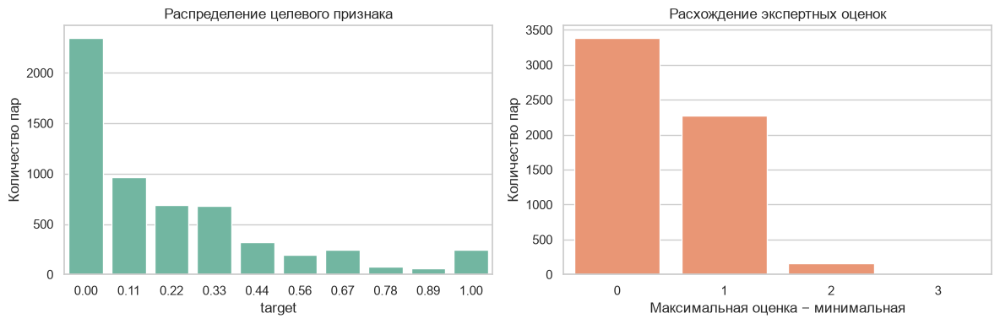

In [35]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

sns.barplot(
    x=[f'{value:.2f}' for value in target_counts.index],
    y=target_counts.values,
    color=PALETTE[0],
    ax=axes[0]
)
axes[0].set(
    title='Распределение целевого признака',
    xlabel='target',
    ylabel='Количество пар'
)

sns.barplot(
    x=spread_counts.index,
    y=spread_counts.values,
    color=PALETTE[1],
    ax=axes[1]
)
axes[1].set(
    title='Расхождение экспертных оценок',
    xlabel='Максимальная оценка − минимальная',
    ylabel='Количество пар'
)

plt.tight_layout()
plt.show()

Распределение целевого признака смещено в сторону низких оценок соответствия. Наиболее часто встречается `target = 0`: такие пары составляют 40,4% выборки. Для них все три эксперта поставили минимальную оценку - изображение и описание не соответствуют друг другу.

В 58,2% пар оценки экспертов полностью совпадают. Расхождение между максимальной и минимальной оценками на два балла и более наблюдается только в 2,7% пар. Таким образом, сильные разногласия между экспертами встречаются редко.

Посмотрим, как фильтрация изменила распределение оценок.

In [36]:
pd.DataFrame({
    'Исходные пары': model_df['target'].describe(),
    'После фильтрации': clean_df['target'].describe()
}).T

,count,mean,std,min,25%,50%,75%,max
Исходные пары,5822.0000,0.2159,0.2687,0.0000,0.0000,0.1111,0.3333,1.0000
После фильтрации,3162.0000,0.2808,0.2973,0.0000,0.0000,0.2222,0.4444,1.0000


In [37]:
text_lengths = (train_df.drop_duplicates('query_id')['query_text']
    .str.split().str.len())
text_lengths.describe()

count   977.0000
mean     11.7646
std       3.9339
min       2.0000
25%       9.0000
50%      11.0000
75%      14.0000
max      34.0000
Name: query_text, dtype: float64

Максимальная длина 34, минимальная 2, в среднем 12 слов.

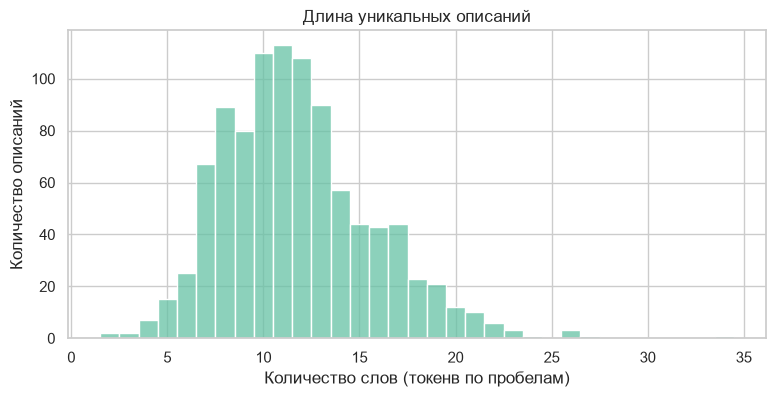

In [38]:
plt.figure(figsize=(9, 4))
sns.histplot(text_lengths, discrete=True, color=PALETTE[0])
plt.title('Длина уникальных описаний')
plt.xlabel('Количество слов (токенв по пробелам)')
plt.ylabel('Количество описаний')
plt.show()

Описания преимущественно короткие: медианная длина составляет 11 токенов по пробелам, средняя - 11,8. Длина изменяется от 2 до 34 токенов; примерно 66,2% описаний имеют длину от 8 до 14.

Каждое описание учтено один раз по `query_id`, поэтому его повторение в разных парах не увеличивает его вес на графике.

In [39]:
examples = pd.concat([
    clean_df.loc[clean_df['target'].eq(0)].sample(2, random_state=RANDOM_STATE),
    clean_df.loc[clean_df['target'].ge(.8)].sample(2, random_state=RANDOM_STATE)
])

Для визуальной проверки разметки рассмотрим несколько пар 'изображение - описание': две с нулевой и две с высокой экспертной оценкой соответствия. Для каждой пары выведем фотографию, описание, оценки трёх экспертов и итоговый `target`.

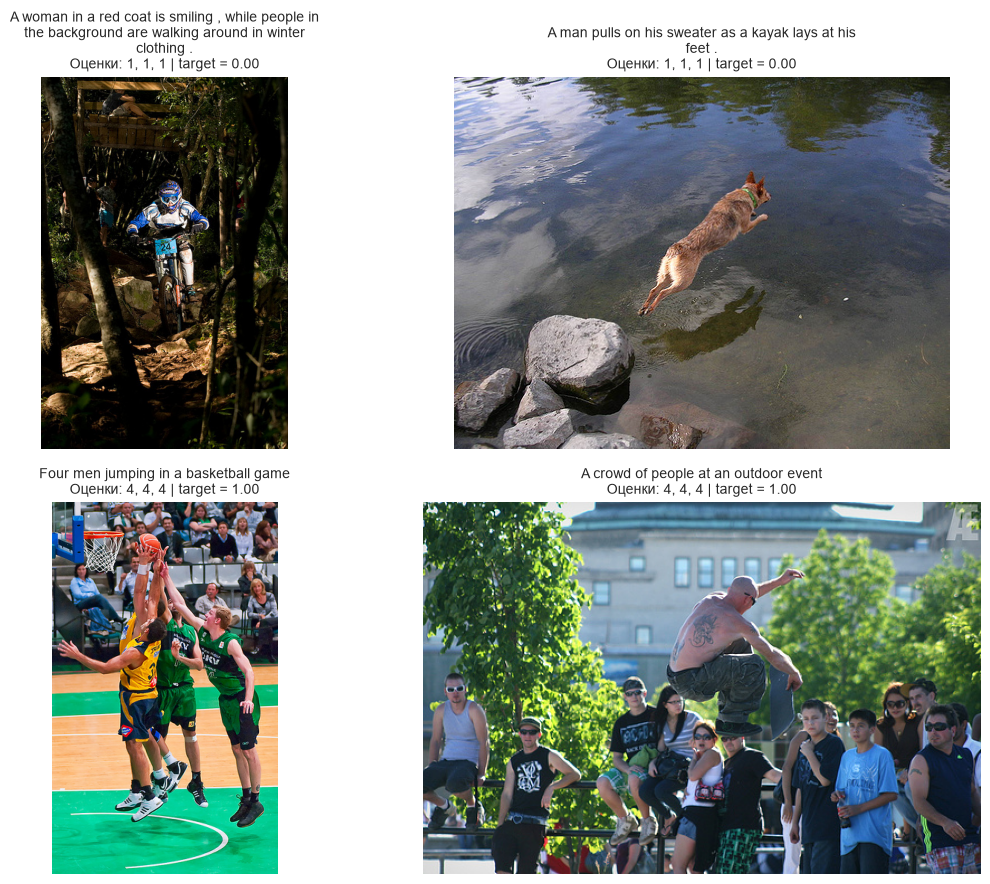

In [40]:
fig, axes = plt.subplots(2, 2, figsize=(12, 9))

for ax, (_, row) in zip(axes.flat, examples.iterrows()):
    with Image.open(TRAIN_IMAGES_DIR / row['image']) as image:
        ax.imshow(image)

    scores = ', '.join(str(row[column]) for column in ['expert_1', 
                                                       'expert_2', 
                                                       'expert_3'])

    ax.set_title(
        fill(row['query_text'], width=50)
        + f'\nОценки: {scores} | target = {row["target"]:.2f}',
        fontsize=10
    )
    ax.axis('off')

plt.tight_layout()
plt.show()

В показанных примерах экспертные оценки согласуются с содержанием пар. В верхнем ряду описания не соответствуют фотографиям: текст о женщине сопоставлен с велосипедистом, а текст о мужчине с каяком - с прыгающей собакой. Все эксперты поставили этим парам минимальные оценки.

В нижнем ряду описания передают изображённые сцены: баскетбольный матч и группу людей на мероприятии. Эти пары получили максимальные оценки. Примеры иллюстрируют различие между низким и высоким соответствием, но не позволяют оценить качество разметки всей выборки.

In [41]:
crowd_df[['crowd_share', 'votes_match', 'votes_mismatch']].describe().T

,count,mean,std,min,25%,50%,75%,max
crowd_share,47830.0000,0.0688,0.2075,0.0000,0.0000,0.0000,0.0000,1.0000
votes_match,47830.0000,0.2085,0.6289,0.0000,0.0000,0.0000,0.0000,5.0000
votes_mismatch,47830.0000,2.8202,0.6567,0.0000,3.0000,3.0000,3.0000,6.0000


In [42]:
crowd_values = crowd_df['crowd_share'].round(2)

In [43]:
crowd_values.value_counts()

crowd_share
0.0000    41970
0.3300     3000
0.6700     1360
1.0000     1323
0.2500       96
0.5000       27
0.2000       22
0.7500        9
0.6000        8
0.4000        8
0.8000        4
0.1700        3
Name: count, dtype: int64

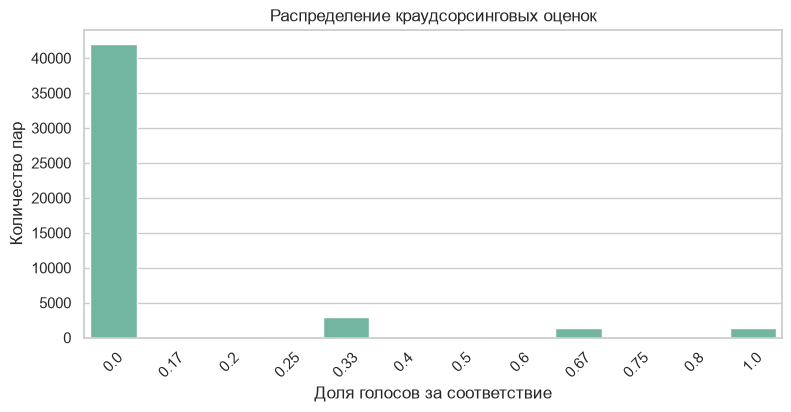

In [44]:
plt.figure(figsize=(9, 4))
sns.countplot(x=crowd_values, order=sorted(crowd_values.unique()), 
              color=PALETTE[0])
plt.title('Распределение краудсорсинговых оценок')
plt.xlabel('Доля голосов за соответствие')
plt.ylabel('Количество пар')
plt.xticks(rotation=45)
plt.show()

Краудсорсинговые оценки распределены неравномерно: 87,7% пар получили нулевую долю голосов за соответствие. Для этих пар все исполнители отметили несоответствие изображения описанию.

Основные значения доли голосов - 0, 1/3, 2/3 и 1. Это связано с тем, что 97,8% пар оценены тремя исполнителями. Дополнительные значения возникают у пар с четырьмя, пятью и шестью голосами и встречаются значительно реже.

Для сравнения экспертной и краудсорсинговой разметки далее рассмотрим общие пары, поскольку исходные таблицы содержат разные наборы наблюдений.

Доля нулевого крауда:

In [45]:
crowd_df['crowd_share'].eq(0).mean()

np.float64(0.8774827514112482)

**Вывод по ИАД.**

В исходной экспертной разметке 40,4% пар получили нулевой таргет. Все эксперты согласны у 58,2% пар, а расхождение хотя бы на два балла встречается у 2,7%. В данных преобладают пары со слабым соответствием. Это важно учитывать при оценке предсказаний и разборе ошибок. Неоднозначные оценки без оснований не удаляем.

Описания короткие: в среднем около 12 слов, максимум - 34. После фильтрации распределение таргета изменилось. Обучение и оценку проводим на одинаково подготовленных данных. В полном наборе крауда 87,7% нулевых оценок.

# 4. Корреляционный анализ

Сравним источники разметки. Экспертные оценки и голоса крауда здесь изучаются
как оценки соответствия; в признаки модели эти столбцы не передаём.

In [46]:
scores_df = model_df[['image', 'query_id', 'target']].merge(
    crowd_df,
    on=['image', 'query_id'],
    how='left',
    validate='one_to_one'
)

In [47]:
scores_df.info()

<class 'pandas.DataFrame'>
RangeIndex: 5822 entries, 0 to 5821
Data columns (total 6 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   image           5822 non-null   str    
 1   query_id        5822 non-null   str    
 2   target          5822 non-null   float64
 3   crowd_share     2329 non-null   float64
 4   votes_match     2329 non-null   float64
 5   votes_mismatch  2329 non-null   float64
dtypes: float64(4), str(2)
memory usage: 273.0 KB


In [48]:
2329/5822

0.4000343524562006

Всего обучающих пар 5822, а с оценкой крауда уже 2329, покрытие около 40%.

Оставим только те, у которых есть оценка крауда.

In [49]:
common_scores = scores_df.dropna(subset=['crowd_share'])

common_scores.describe().T

,count,mean,std,min,25%,50%,75%,max
target,2329.0000,0.4029,0.3060,0.0000,0.1111,0.3333,0.6667,1.0000
crowd_share,2329.0000,0.1983,0.3433,0.0000,0.0000,0.0000,0.3333,1.0000
votes_match,2329.0000,0.6028,1.0449,0.0000,0.0000,0.0000,1.0000,5.0000
votes_mismatch,2329.0000,2.4341,1.0572,0.0000,2.0000,3.0000,3.0000,6.0000


Значения выглядят корректно

Изучим связь между нормализованной экспертной оценкой, долей положительных голосов крауда и количеством голосов за и против соответствия. Для корректного сравнения используем только пары, представленные в обоих источниках разметки.

In [50]:
score_correlations = common_scores[
    ['target', 'crowd_share', 'votes_match', 'votes_mismatch']].corr()
score_correlations

,target,crowd_share,votes_match,votes_mismatch
target,1.0000,0.7908,0.7869,-0.7769
crowd_share,0.7908,1.0000,0.9957,-0.9822
votes_match,0.7869,0.9957,1.0000,-0.9731
votes_mismatch,-0.7769,-0.9822,-0.9731,1.0000


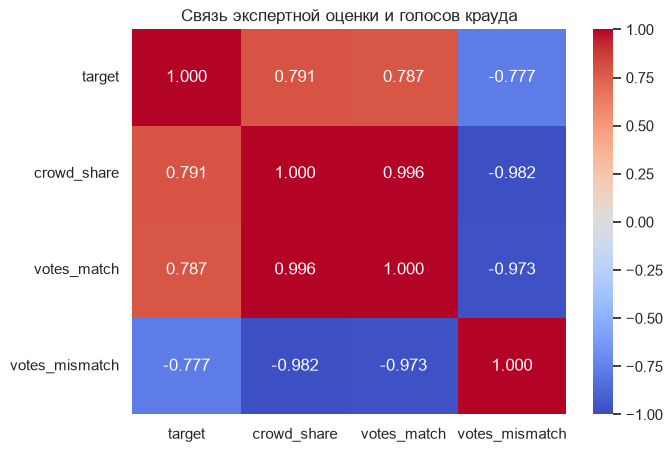

In [51]:
plt.figure(figsize=(7, 5))
sns.heatmap(score_correlations, annot=True, fmt='.3f', cmap='coolwarm', 
            vmin=-1, vmax=1)
plt.title('Связь экспертной оценки и голосов крауда')
plt.show()

Экспертная оценка положительно связана с долей положительных голосов крауда: коэффициент корреляции составляет 0,791. Связь с количеством голосов за соответствие также положительная, а с количеством голосов против - отрицательная.

Высокая корреляция между показателями крауда объясняется тем, что доля положительных голосов рассчитывается из количества голосов за и против. Для оценки численного согласия экспертов и крауда дополнительно рассмотрим диаграмму рассеяния и величину расхождения.

Проверим, насколько близки значения экспертных и краудсорсинговых оценок для отдельных пар. Красная пунктирная линия соответствует их численному равенству. Отклонение точки от этой линии показывает различие между двумя оценками.

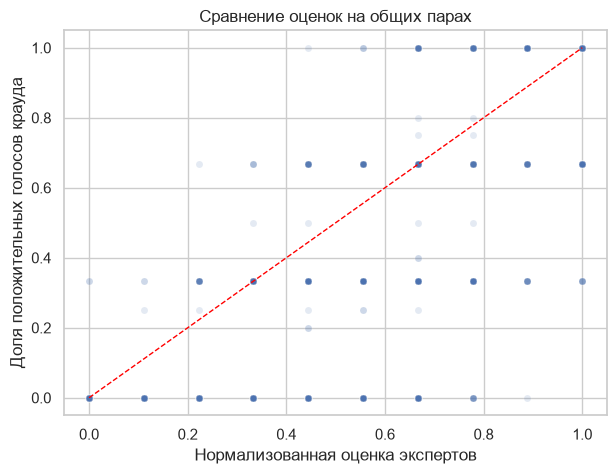

In [52]:
plt.figure(figsize=(7, 5))
sns.scatterplot(data=common_scores, x='target', y='crowd_share', alpha=.15, s=25)
plt.plot([0, 1], [0, 1], '--', color='red', linewidth=1)
plt.xlabel('Нормализованная оценка экспертов')
plt.ylabel('Доля положительных голосов крауда')
plt.title('Сравнение оценок на общих парах')
plt.show()

Посмотрим на среднее абсолютное расхождение

In [53]:
common_scores[['target', 'crowd_share']].mean()

target        0.4029
crowd_share   0.1983
dtype: float64

In [54]:
(common_scores['target'] - common_scores['crowd_share']).abs().mean()

np.float64(0.22647297361767094)

Экспертные и краудсорсинговые оценки связаны: их корреляция составляет 0,791. При этом среднее абсолютное расхождение равно 0,226 на шкале от 0 до 1. На диаграмме также видны пары, которым эксперты дали высокую оценку, а крауд - низкую.

Таким образом, источники отражают общую тенденцию соответствия, но их численные оценки не взаимозаменяемы. Кроме того, экспертный балл описывает степень соответствия, а краудсорсинговая оценка - долю положительных ответов. В текущем проекте целевую переменную формируем из экспертных оценок, а крауд используем для дополнительного анализа.

**Вывод по корреляционному анализу.**

Для 2329 из 5822 экспертных пар есть оценка крауда - это 40%. На общих парах корреляция составляет 0,791, но средние оценки различаются: 0,40 у экспертов и 0,20 у крауда. Среднее абсолютное расхождение равно 0,226.

Источники связаны, но не взаимозаменяемы. Отсутствие разметки не означает ноль. Для обучения всех трёх подходов используем среднее экспертных оценок. Крауд оставляем для анализа качества разметки.

# 5. Feature engineering

Для обязательной части ТЗ используем признаки ResNet50 и BERT. Затем подготовим альтернативное представление пары через CLIP. Все кодировщики заморожены: получение векторов не обучает их на наших данных.

## ResNet50

Загрузим предобученные веса и заменим последний классификационный слой на `Identity`. Используем обработку входа из настроек весов. Каждая фотография получит 2048 признаков.

In [55]:
image_weights = ResNet50_Weights.DEFAULT
image_transform = image_weights.transforms()

In [56]:
image_model = resnet50(weights=image_weights)
image_model.fc = nn.Identity()
image_model.requires_grad_(False)
image_model = image_model.to(DEVICE).eval()

Напишем функцию которая обрабатывает фотографии пачками и собирает их векторы

In [57]:
def extract_image_vectors(image_names, image_dir, batch_size=32):
    vectors = []

    for start in tqdm(range(0, len(image_names), batch_size)):
        batch_names = image_names[start:start + batch_size]
        batch = []

        for name in batch_names:
            with Image.open(image_dir / name) as image:
                batch.append(image_transform(image.convert('RGB')))

        batch = torch.stack(batch).to(DEVICE)

        with torch.inference_mode():
            batch_vectors = image_model(batch)

        vectors.append(batch_vectors.cpu().numpy())

    return np.concatenate(vectors, axis=0)

Соберём уникальные фотографии, чтобы каждую обработать только один раз. Полученные векторы потом используем во всех парах с этими фотографиями.

In [58]:
image_names = sorted(clean_df['image'].unique())

In [59]:
image_vectors = extract_image_vectors(image_names, TRAIN_IMAGES_DIR)

  0%|          | 0/22 [00:00<?, ?it/s]

In [60]:
image_vectors.shape

(703, 2048)

703 фотографии и 2048 признаков на каждую из них.

In [61]:
image_vectors.dtype

dtype('float32')

Все отлично, мы прогнали 703 фотки по 3 канала через ResNet50 и получили 703 фотки и по 2048 признаков.

## BERT

Используем `bert-base-uncased`: он возвращает по 768 признаков для каждого токена. Усредним представления без padding и получим один вектор на описание. Исходный текст сохраняем: удаление стоп-слов и лемматизация перед BERT здесь не требуются.

In [62]:
TEXT_MODEL_NAME = 'google-bert/bert-base-uncased'

In [63]:
text_tokenizer = AutoTokenizer.from_pretrained(
    TEXT_MODEL_NAME, cache_dir=FEATURES_DIR / 'bert_cache'
)

In [64]:
text_model = AutoModel.from_pretrained(
    TEXT_MODEL_NAME, cache_dir=FEATURES_DIR / 'bert_cache',
    add_pooling_layer=False
)

Loading weights:   0%|          | 0/197 [00:00<?, ?it/s]

[transformers] BertModel LOAD REPORT from: google-bert/bert-base-uncased
Key                                        | Status     |  | 
-------------------------------------------+------------+--+-
cls.seq_relationship.weight                | UNEXPECTED |  | 
cls.predictions.bias                       | UNEXPECTED |  | 
cls.predictions.transform.dense.bias       | UNEXPECTED |  | 
bert.pooler.dense.bias                     | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED |  | 
cls.predictions.transform.dense.weight     | UNEXPECTED |  | 
bert.pooler.dense.weight                   | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED |  | 
cls.seq_relationship.bias                  | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


In [65]:
text_model.requires_grad_(False)

BertModel(
  (embeddings): BertEmbeddings(
    (word_embeddings): Embedding(30522, 768, padding_idx=0)
    (position_embeddings): Embedding(512, 768)
    (token_type_embeddings): Embedding(2, 768)
    (LayerNorm): LayerNorm((768,), eps=1e-12, elementwise_affine=True, bias=True)
    (dropout): Dropout(p=0.1, inplace=False)
  )
  (encoder): BertEncoder(
    (layer): ModuleList(
      (0-11): 12 x BertLayer(
        (attention): BertAttention(
          (self): BertSelfAttention(
            (query): Linear(in_features=768, out_features=768, bias=True)
            (key): Linear(in_features=768, out_features=768, bias=True)
            (value): Linear(in_features=768, out_features=768, bias=True)
            (dropout): Dropout(p=0.1, inplace=False)
          )
          (output): BertSelfOutput(
            (dense): Linear(in_features=768, out_features=768, bias=True)
            (LayerNorm): LayerNorm((768,), eps=1e-12, elementwise_affine=True, bias=True)
            (dropout): Dropout(p=

In [66]:
text_model = text_model.to(DEVICE).eval()

Напишем функцию для обработки описаний пачками. Для каждого описания усредним векторы токенов, исключив padding.

In [67]:
def extract_text_vectors(texts, batch_size=16):
    vectors = []

    for start in tqdm(range(0, len(texts), batch_size)):
        batch = text_tokenizer(
            texts[start:start + batch_size],
            padding=True,
            truncation=True,
            max_length=128,
            return_tensors='pt'
        ).to(DEVICE)

        with torch.inference_mode():
            hidden = text_model(**batch).last_hidden_state
            mask = batch['attention_mask'].unsqueeze(-1).float()

            batch_vectors = (
                (hidden * mask).sum(dim=1)
                / mask.sum(dim=1)
            )

        vectors.append(batch_vectors.cpu().numpy())

    return np.concatenate(vectors, axis=0)

Соберём уникальные описания и сохраним их идентификаторы в том же порядке. Так каждый полученный вектор будет связан со своим описанием.

In [68]:
text_df = (clean_df[['query_id', 'query_text']].drop_duplicates('query_id')
    .sort_values('query_id'))

In [69]:
query_ids = text_df['query_id'].tolist()
texts = text_df['query_text'].tolist()

In [70]:
text_vectors = extract_text_vectors(texts)

  0%|          | 0/42 [00:00<?, ?it/s]

In [71]:
text_vectors.shape

(665, 768)

Получили 665 описаний по 768 признаков.

Проверим длину описаний после токенизации, чтобы понять, достаточно ли выбранного лимита в 128 токенов.

In [72]:
token_lengths = pd.Series([len(ids) for ids in text_tokenizer(texts)['input_ids']])
token_lengths.describe()

count   665.0000
mean     14.0556
std       3.9749
min       4.0000
25%      11.0000
50%      14.0000
75%      16.0000
max      36.0000
dtype: float64

Самое длинное описание занимает 36 токенов. Лимит 128 не обрезает тексты нашей выборки.

## CLIP как источник признаков

Используем два готовых кодировщика CLIP для изображений и описаний. Каждый возвращает вектор длины 512. Веса не дообучаем. Полученные векторы объединим, а экспертную оценку будет предсказывать отдельная обучаемая FFN.

In [73]:
CLIP_MODEL_NAME = 'openai/clip-vit-base-patch32'
CLIP_CACHE_DIR = FEATURES_DIR / 'prefabricated_5_improved' / 'clip_cache'

In [74]:
clip_processor = AutoProcessor.from_pretrained(CLIP_MODEL_NAME, 
                                               cache_dir=CLIP_CACHE_DIR)

In [75]:
clip_model = CLIPModel.from_pretrained(CLIP_MODEL_NAME, cache_dir=CLIP_CACHE_DIR)

Loading weights:   0%|          | 0/398 [00:00<?, ?it/s]

In [76]:
clip_model.requires_grad_(False)

CLIPModel(
  (text_model): CLIPTextModel(
    (embeddings): CLIPTextEmbeddings(
      (token_embedding): Embedding(49408, 512)
      (position_embedding): Embedding(77, 512)
    )
    (encoder): CLIPEncoder(
      (layers): ModuleList(
        (0-11): 12 x CLIPEncoderLayer(
          (self_attn): CLIPAttention(
            (k_proj): Linear(in_features=512, out_features=512, bias=True)
            (v_proj): Linear(in_features=512, out_features=512, bias=True)
            (q_proj): Linear(in_features=512, out_features=512, bias=True)
            (out_proj): Linear(in_features=512, out_features=512, bias=True)
          )
          (layer_norm1): LayerNorm((512,), eps=1e-05, elementwise_affine=True, bias=True)
          (mlp): CLIPMLP(
            (activation_fn): QuickGELUActivation()
            (fc1): Linear(in_features=512, out_features=2048, bias=True)
            (fc2): Linear(in_features=2048, out_features=512, bias=True)
          )
          (layer_norm2): LayerNorm((512,), eps=1

In [77]:
clip_model = clip_model.to(DEVICE).eval()

Напишем две функции для CLIP: одну для фотографий, другую для описаний. В обоих случаях приведём полученные векторы к единичной длине.

In [78]:
def extract_clip_images(names, directory, batch_size=32):
    vectors = []
    for start in tqdm(range(0, len(names), batch_size)):
        images = []
        for name in names[start:start + batch_size]:
            with Image.open(directory / name) as image:
                images.append(image.convert('RGB'))
        batch = clip_processor(images=images, return_tensors='pt').to(DEVICE)
        with torch.inference_mode():
            features = clip_model.visual_projection(clip_model.vision_model(**batch).pooler_output)
            features = nn.functional.normalize(features, dim=1)
        vectors.append(features.cpu().numpy())
    return np.concatenate(vectors)

In [79]:
def extract_clip_texts(texts, batch_size=32):
    vectors = []
    for start in range(0, len(texts), batch_size):
        batch = clip_processor(
            text=texts[start:start + batch_size], padding=True,
            truncation=True, max_length=77, return_tensors='pt'
        ).to(DEVICE)
        with torch.inference_mode():
            features = clip_model.text_projection(clip_model.text_model(**batch).pooler_output)
            features = nn.functional.normalize(features, dim=1)
        vectors.append(features.cpu().numpy())
    return np.concatenate(vectors)

Получим CLIP-признаки для тех же фотографий и описаний. Это позволит сравнить два варианта признаков на одинаковых парах.

In [80]:
clip_image_vectors = extract_clip_images(image_names, TRAIN_IMAGES_DIR)

  0%|          | 0/22 [00:00<?, ?it/s]

In [81]:
clip_text_vectors = extract_clip_texts(texts)

In [82]:
clip_image_vectors.shape, clip_text_vectors.shape

((703, 512), (665, 512))

Получили по 512 признаков для каждой фотографии и каждого описания.

**Вывод по feature engineering.**

Векторизованы 703 фотографии и 665 описаний. ResNet50 даёт 2048 признаков, BERT - 768; после объединения получим 2816 признаков пары. У CLIP по 512 признаков изображения и текста; объединённый вектор имеет длину 1024.

Все кодировщики заморожены. Векторы считаем один раз для каждого объекта.

# 6. Подготовка данных к обучению

Разделим экспертные пары по фотографиям: около 70% в train и 30% в val. На val выбираем архитектуру, параметры и лучшую эпоху. Внешние test_images и test_queries оставляем для финальной демонстрации поиска выбранной модели.

Одно изображение со всеми его парами находится в одной выборке. Описания между выборками могут повторяться: проверяем перенос на новые фотографии.

Во втором ТЗ приведён пример разбиения 7:3. Выборку для подбора параметров называем val, чтобы отличать её от внешнего test_images/test_queries.

In [83]:
splitter = GroupShuffleSplit(n_splits=1, test_size=.3, random_state=RANDOM_STATE)
train_idx, val_idx = next(splitter.split(clean_df, groups=clean_df['image']))

In [84]:
train_part = clean_df.iloc[train_idx].copy()
val_part = clean_df.iloc[val_idx].copy()

In [85]:
parts = {'train': train_part, 'val': val_part}

In [86]:
pd.DataFrame([{
    'Выборка': name, 'Пар': len(part), 'Фотографий': part['image'].nunique(),
    'Описаний': part['query_id'].nunique()
} for name, part in parts.items()]).set_index('Выборка')

,Пар,Фотографий,Описаний
Выборка,,,
train,2221,492,622
val,941,211,481


Составим словари, чтобы по имени фотографии или идентификатору описания находить нужную строку в матрице признаков.

In [87]:
image_index = {name: i for i, name in enumerate(image_names)}

In [88]:
text_index = {query_id: i for i, query_id in enumerate(query_ids)}

Для каждой пары объединим вектор фотографии с вектором описания. Целевые оценки сохраним отдельно.

In [89]:
def make_features(part, image_features, text_features):
    image_idx = part['image'].map(image_index).to_numpy()
    text_idx = part['query_id'].map(text_index).to_numpy()
    X = np.concatenate([image_features[image_idx], text_features[text_idx]], axis=1)
    y = part['target'].to_numpy(dtype=np.float32)
    return X, y

Подготовим train и val для обоих вариантов признаков. Пары и целевые оценки в обоих случаях одинаковые.

In [90]:
X_train, y_train = make_features(train_part, image_vectors, text_vectors)
X_val, y_val = make_features(val_part, image_vectors, text_vectors)

In [91]:
X_train_clip, _ = make_features(train_part, clip_image_vectors, clip_text_vectors)
X_val_clip, _ = make_features(val_part, clip_image_vectors, clip_text_vectors)

In [92]:
pd.DataFrame({
    'Признаки': ['ResNet50 + BERT', 'CLIP'],
    'Train': [X_train.shape, X_train_clip.shape],
    'Val': [X_val.shape, X_val_clip.shape],
})

,Признаки,Train,Val
0,ResNet50 + BERT,"(2221, 2816)","(941, 2816)"
1,CLIP,"(2221, 1024)","(941, 1024)"


**Вывод по подготовке данных.**

В train 2221 пара и 492 фотографии, в val - 941 пара и 211 фотографий. Пересечений по фотографиям нет. Оба набора признаков относятся к одним и тем же парам и одному таргету. Внешние тестовые фотографии отделены от этих данных.

# 7. Обучение и сравнение моделей

Сравним LinearRegression и две FFN: на признаках ResNet50 + BERT и на признаках CLIP. Все предсказывают нормализованную экспертную оценку. Основная и единственная метрика сравнения - RMSE, корень из средней квадратичной ошибки.

RMSE измеряется в единицах таргета и сильнее штрафует крупные ошибки. Например, для ошибок 0,1 и 0,3 она равна sqrt((0.1² + 0.3²) / 2) = 0,224. Меньшее значение лучше; RMSE 0,2 не означает точность 80%.

Для обучения сетей используем MSE. У FFN на выходе Sigmoid, поэтому прогноз находится в [0, 1]. У линейной регрессии ограничиваем прогноз тем же диапазоном. Все параметры выбираем на val. Её RMSE - оценка для выбора, а не независимый финальный результат. Внешний test используем только для выбранного победителя.

## 7.1. Линейная регрессия

Обучим обязательную линейную модель на объединённых признаках ResNet50 и BERT. Масштабирование включено в тот же пайплайн.

In [93]:
linear_pipeline = Pipeline([
    ('scaler', StandardScaler()),
    ('model', LinearRegression())
])

In [94]:
linear_pipeline.fit(X_train, y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('scaler', ...), ('model', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,2816
,"copy copy: bool, default=TrueIf False, try to avoid a copy and do inplace scaling instead.This is not guaranteed to always work inplace; e.g. if the data isnot a NumPy array or scipy.sparse CSR matrix, a copy may still bereturned.",True
,"with_mean with_mean: bool, default=TrueIf True, center the data before scaling.This does not work (and will raise an exception) when attempted onsparse matrices, because centering them entails building a densematrix which in common use cases is likely to be too large to fit inmemory.",True
,"with_std with_std: bool, default=TrueIf True, scale the data to unit variance (or equivalently,unit standard deviation).",True
Name,Type,Value
"mean_ mean_: ndarray of shape (n_features,) or NoneThe mean value for each feature in the training set.Equal to ``None`` when ``with_mean=False`` and ``with_std=False``.","ndarray[float64](2816,)","[ 0.14, 0.01, 0.08,...,-0.21, 0.01, 0.01]"


Получим прогнозы на валидации. Линейная регрессия может выдавать значения за пределами шкалы таргета, поэтому ограничим их диапазоном [0, 1].

In [95]:
linear_val_pred = np.clip(linear_pipeline.predict(X_val), 0, 1)

In [96]:
linear_rmse = np.sqrt(mean_squared_error(y_val, linear_val_pred))
linear_rmse

np.float64(0.3544570863438075)

**Вывод по линейной регрессии.**

Val RMSE равна 0.3545. Масштабирование обучено на train, прогнозы ограничены диапазоном [0, 1]. Линейная модель служит простой точкой сравнения. Для конкатенированных векторов она складывает отдельные вклады текста и фотографии, поэтому её возможности описывать их совместное соответствие ограничены.

## 7.2. Архитектура и обучение FFN

Проверим сети с одним, двумя и тремя скрытыми слоями. Каждый скрытый блок: Linear -> BatchNorm при его включении -> ReLU -> Dropout. На выходе один нейрон с Sigmoid. Размер входа берём из матрицы признаков: 2816 или 1024.

StandardScaler масштабирует входные признаки, BatchNorm - активации скрытых слоёв. При обучении BatchNorm использует статистики батча, при оценке - накопленные статистики. Поэтому перед валидацией и предсказаниями переводим сеть в eval.

Оптимизатор AdamW, максимум 100 эпох. Если Val RMSE не улучшается 10 эпох, останавливаемся и восстанавливаем веса лучшей эпохи.

In [97]:
def create_ffn(input_size, hidden_layers, dropout, batch_norm):
    layers = []
    previous_size = input_size
    for hidden_size in hidden_layers:
        layers.append(nn.Linear(previous_size, hidden_size))
        if batch_norm:
            layers.append(nn.BatchNorm1d(hidden_size))
        layers.extend([nn.ReLU(), nn.Dropout(dropout)])
        previous_size = hidden_size
    layers.extend([nn.Linear(previous_size, 1), nn.Sigmoid()])
    return nn.Sequential(*layers).to(DEVICE)

Напишем цикл обучения с ранней остановкой. После каждой эпохи будем считать ошибку на train и val и запоминать лучшие веса.

In [98]:
def train_ffn(X, y, X_val, y_val, hidden_layers, dropout, batch_norm,
              lr, batch_size, weight_decay):
    torch.manual_seed(RANDOM_STATE)
    X_t = torch.tensor(X, dtype=torch.float32, device=DEVICE)
    y_t = torch.tensor(y, dtype=torch.float32, device=DEVICE).reshape(-1, 1)
    X_val_t = torch.tensor(X_val, dtype=torch.float32, device=DEVICE)
    y_val_t = torch.tensor(y_val, dtype=torch.float32, device=DEVICE).reshape(-1, 1)
    model = create_ffn(X.shape[1], hidden_layers, dropout, batch_norm)
    optimizer = torch.optim.AdamW(model.parameters(), lr=lr, weight_decay=weight_decay)
    criterion = nn.MSELoss()
    history = {'train_rmse': [], 'val_rmse': []}
    best_rmse = float('inf')
    best_epoch = 0
    bad_epochs = 0

    for epoch in range(1, 101):
        model.train()
        indices = torch.randperm(len(X_t), device=DEVICE)
        for idx in indices.split(batch_size):
            optimizer.zero_grad()
            loss = criterion(model(X_t[idx]), y_t[idx])
            loss.backward()
            optimizer.step()

        model.eval()
        with torch.no_grad():
            train_rmse = criterion(model(X_t), y_t).sqrt().item()
            val_rmse = criterion(model(X_val_t), y_val_t).sqrt().item()
        history['train_rmse'].append(train_rmse)
        history['val_rmse'].append(val_rmse)
        if val_rmse < best_rmse:
            best_rmse = val_rmse
            best_weights = deepcopy(model.state_dict())
            best_epoch = epoch
            bad_epochs = 0
        else:
            bad_epochs += 1
        if bad_epochs >= 10:
            break

    model.load_state_dict(best_weights)
    model.eval()
    print(f'Лучшая эпоха: {best_epoch}, Val RMSE: {best_rmse:.4f}')
    return model, history, best_epoch

Обернём нейросеть в класс с методами fit и predict, чтобы использовать её в Pipeline вместе с масштабированием.

In [99]:
class FFNRegressor(RegressorMixin, BaseEstimator):
    def __init__(self, hidden_layers=(128, 32), dropout=.2, batch_norm=False,
                 lr=.001, batch_size=64, weight_decay=.001):
        self.hidden_layers = hidden_layers
        self.dropout = dropout
        self.batch_norm = batch_norm
        self.lr = lr
        self.batch_size = batch_size
        self.weight_decay = weight_decay

    def fit(self, X, y, X_val, y_val):
        self.model_, self.history_, self.best_epoch_ = train_ffn(
            X, y, X_val, y_val, self.hidden_layers, self.dropout, self.batch_norm,
            self.lr, self.batch_size, self.weight_decay
        )
        return self

    def predict(self, X):
        self.model_.eval()
        with torch.no_grad():
            features = torch.tensor(X, dtype=torch.float32, device=DEVICE)
            return self.model_(features).cpu().numpy().ravel()

In [100]:
def make_ffn_pipeline(**params):
    regressor = FFNRegressor(**params).set_fit_request(X_val=True, y_val=True)
    return Pipeline([
        ('scaler', StandardScaler()),
        ('model', regressor)
    ], transform_input=['X_val'])

Параметр transform_input пропускает X_val через масштабировщик, обученный на train. y_val передаётся без изменения. На валидации масштабировщик не обучается.

## 7.3. Конфигурации сетей

Для каждой группы признаков проверим одинаковые 24 конфигурации: 12 сочетаний архитектуры и параметров, каждое с BatchNorm и без него. Варьируем число и ширину скрытых слоёв, Dropout, learning rate, размер батча и weight decay. Парные варианты позволяют увидеть эффект BatchNorm при остальных равных настройках.

In [101]:
base_configs = [
    dict(hidden_layers=(64,), dropout=0., lr=.001, batch_size=64, weight_decay=.001),
    dict(hidden_layers=(128,), dropout=.2, lr=.001, batch_size=64, weight_decay=.001),
    dict(hidden_layers=(128, 32), dropout=.2, lr=.001, batch_size=64, weight_decay=.001),
    dict(hidden_layers=(128, 32), dropout=.4, lr=.001, batch_size=64, weight_decay=.001),
    dict(hidden_layers=(128, 32), dropout=.2, lr=.0003, batch_size=64, weight_decay=.001),
    dict(hidden_layers=(64, 32), dropout=.2, lr=.001, batch_size=32, weight_decay=.0001),
    dict(hidden_layers=(128, 64), dropout=.3, lr=.001, batch_size=128, weight_decay=.001),
    dict(hidden_layers=(256, 64), dropout=.3, lr=.001, batch_size=64, weight_decay=.001),
    dict(hidden_layers=(256, 64), dropout=.5, lr=.0003, batch_size=64, weight_decay=.01),
    dict(hidden_layers=(256, 64, 16), dropout=.2, lr=.0003, batch_size=64, weight_decay=.001),
    dict(hidden_layers=(512, 128, 32), dropout=.4, lr=.001, batch_size=128, weight_decay=.001),
    dict(hidden_layers=(128, 32), dropout=.2, lr=.003, batch_size=64, weight_decay=.001)
]

In [102]:
configs = [
    {**params, 'batch_norm': batch_norm}
    for params in base_configs for batch_norm in [False, True]
]

In [103]:
pd.DataFrame(configs)

,hidden_layers,dropout,lr,batch_size,weight_decay,batch_norm
0,"(64,)",0.0000,0.0010,64,0.0010,False
1,"(64,)",0.0000,0.0010,64,0.0010,True
2,"(128,)",0.2000,0.0010,64,0.0010,False
3,"(128,)",0.2000,0.0010,64,0.0010,True
4,"(128, 32)",0.2000,0.0010,64,0.0010,False
5,"(128, 32)",0.2000,0.0010,64,0.0010,True
6,"(128, 32)",0.4000,0.0010,64,0.0010,False
7,"(128, 32)",0.4000,0.0010,64,0.0010,True
8,"(128, 32)",0.2000,0.0003,64,0.0010,False
9,"(128, 32)",0.2000,0.0003,64,0.0010,True


Обучим отдельную сеть для каждой конфигурации и сравним минимальные ошибки на валидации. Вернём лучшую модель и таблицу результатов.

In [104]:
def compare_ffn_configs(X_train, y_train, X_val, y_val):
    rows = []
    best_score = float('inf')
    for number, params in enumerate(configs, 1):
        print(f'\nКонфигурация {number}/{len(configs)}: {params}')
        pipeline = make_ffn_pipeline(**params)
        pipeline.fit(X_train, y_train, X_val=X_val, y_val=y_val)
        regressor = pipeline.named_steps['model']
        score = min(regressor.history_['val_rmse'])
        rows.append({
            'config': number, **params,
            'best_epoch': regressor.best_epoch_, 'val_rmse': score
        })
        if score < best_score:
            best_score = score
            best_pipeline = pipeline
    table = pd.DataFrame(rows).sort_values('val_rmse')
    return best_pipeline, table

## 7.4. FFN на признаках ResNet50 + BERT

In [105]:
%%time
best_resnet_ffn, resnet_results = compare_ffn_configs(X_train, y_train, X_val, y_val)


Конфигурация 1/24: {'hidden_layers': (64,), 'dropout': 0.0, 'lr': 0.001, 'batch_size': 64, 'weight_decay': 0.001, 'batch_norm': False}
Лучшая эпоха: 11, Val RMSE: 0.2472

Конфигурация 2/24: {'hidden_layers': (64,), 'dropout': 0.0, 'lr': 0.001, 'batch_size': 64, 'weight_decay': 0.001, 'batch_norm': True}
Лучшая эпоха: 21, Val RMSE: 0.2368

Конфигурация 3/24: {'hidden_layers': (128,), 'dropout': 0.2, 'lr': 0.001, 'batch_size': 64, 'weight_decay': 0.001, 'batch_norm': False}
Лучшая эпоха: 61, Val RMSE: 0.2406

Конфигурация 4/24: {'hidden_layers': (128,), 'dropout': 0.2, 'lr': 0.001, 'batch_size': 64, 'weight_decay': 0.001, 'batch_norm': True}
Лучшая эпоха: 22, Val RMSE: 0.2373

Конфигурация 5/24: {'hidden_layers': (128, 32), 'dropout': 0.2, 'lr': 0.001, 'batch_size': 64, 'weight_decay': 0.001, 'batch_norm': False}
Лучшая эпоха: 20, Val RMSE: 0.2362

Конфигурация 6/24: {'hidden_layers': (128, 32), 'dropout': 0.2, 'lr': 0.001, 'batch_size': 64, 'weight_decay': 0.001, 'batch_norm': True}
Лу

In [106]:
resnet_results.head(10)

,config,hidden_layers,dropout,lr,batch_size,weight_decay,batch_norm,best_epoch,val_rmse
12,13,"(128, 64)",0.3000,0.0010,128,0.0010,False,44,0.2296
5,6,"(128, 32)",0.2000,0.0010,64,0.0010,True,39,0.2305
18,19,"(256, 64, 16)",0.2000,0.0003,64,0.0010,False,55,0.2310
7,8,"(128, 32)",0.4000,0.0010,64,0.0010,True,69,0.2315
21,22,"(512, 128, 32)",0.4000,0.0010,128,0.0010,True,44,0.2316
20,21,"(512, 128, 32)",0.4000,0.0010,128,0.0010,False,37,0.2328
15,16,"(256, 64)",0.3000,0.0010,64,0.0010,True,27,0.2330
9,10,"(128, 32)",0.2000,0.0003,64,0.0010,True,28,0.2333
17,18,"(256, 64)",0.5000,0.0003,64,0.0100,True,40,0.2340
14,15,"(256, 64)",0.3000,0.0010,64,0.0010,False,30,0.2346


In [107]:
best_resnet_ffn.named_steps['model'].model_

Sequential(
  (0): Linear(in_features=2816, out_features=128, bias=True)
  (1): ReLU()
  (2): Dropout(p=0.3, inplace=False)
  (3): Linear(in_features=128, out_features=64, bias=True)
  (4): ReLU()
  (5): Dropout(p=0.3, inplace=False)
  (6): Linear(in_features=64, out_features=1, bias=True)
  (7): Sigmoid()
)

**Вывод по FFN на ResNet50 + BERT.**

Лучшая сеть получила Val RMSE 0.2296. Архитектура: 2816 -> 128 -> 64 -> 1. После скрытых слоёв применяются ReLU и Dropout 0.3, на выходе - Sigmoid. В выбранной конфигурации BatchNorm отключён.

Learning rate - 0.001, batch size - 128, weight decay - 0.001. Лучшие веса получены на эпохе 44. FFN снижает ошибку относительно линейной регрессии на той же валидации.

## 7.5. FFN на признаках CLIP

Используем ту же процедуру обучения, конфигурации и экспертный таргет. Размер входа теперь 1024. Обучаются только веса новой FFN; кодировщики CLIP заморожены.

In [108]:
%%time
best_clip_ffn, clip_results = compare_ffn_configs(X_train_clip, y_train, X_val_clip, y_val)


Конфигурация 1/24: {'hidden_layers': (64,), 'dropout': 0.0, 'lr': 0.001, 'batch_size': 64, 'weight_decay': 0.001, 'batch_norm': False}
Лучшая эпоха: 9, Val RMSE: 0.2133

Конфигурация 2/24: {'hidden_layers': (64,), 'dropout': 0.0, 'lr': 0.001, 'batch_size': 64, 'weight_decay': 0.001, 'batch_norm': True}
Лучшая эпоха: 18, Val RMSE: 0.2195

Конфигурация 3/24: {'hidden_layers': (128,), 'dropout': 0.2, 'lr': 0.001, 'batch_size': 64, 'weight_decay': 0.001, 'batch_norm': False}
Лучшая эпоха: 13, Val RMSE: 0.2108

Конфигурация 4/24: {'hidden_layers': (128,), 'dropout': 0.2, 'lr': 0.001, 'batch_size': 64, 'weight_decay': 0.001, 'batch_norm': True}
Лучшая эпоха: 9, Val RMSE: 0.2089

Конфигурация 5/24: {'hidden_layers': (128, 32), 'dropout': 0.2, 'lr': 0.001, 'batch_size': 64, 'weight_decay': 0.001, 'batch_norm': False}
Лучшая эпоха: 20, Val RMSE: 0.2091

Конфигурация 6/24: {'hidden_layers': (128, 32), 'dropout': 0.2, 'lr': 0.001, 'batch_size': 64, 'weight_decay': 0.001, 'batch_norm': True}
Лучш

In [109]:
clip_results.head(10)

,config,hidden_layers,dropout,lr,batch_size,weight_decay,batch_norm,best_epoch,val_rmse
12,13,"(128, 64)",0.3000,0.0010,128,0.0010,False,24,0.2034
21,22,"(512, 128, 32)",0.4000,0.0010,128,0.0010,True,18,0.2044
20,21,"(512, 128, 32)",0.4000,0.0010,128,0.0010,False,30,0.2049
14,15,"(256, 64)",0.3000,0.0010,64,0.0010,False,18,0.2057
16,17,"(256, 64)",0.5000,0.0003,64,0.0100,False,22,0.2057
13,14,"(128, 64)",0.3000,0.0010,128,0.0010,True,29,0.2059
19,20,"(256, 64, 16)",0.2000,0.0003,64,0.0010,True,35,0.2060
11,12,"(64, 32)",0.2000,0.0010,32,0.0001,True,25,0.2064
18,19,"(256, 64, 16)",0.2000,0.0003,64,0.0010,False,38,0.2075
10,11,"(64, 32)",0.2000,0.0010,32,0.0001,False,18,0.2081


In [110]:
best_clip_ffn.named_steps['model'].model_

Sequential(
  (0): Linear(in_features=1024, out_features=128, bias=True)
  (1): ReLU()
  (2): Dropout(p=0.3, inplace=False)
  (3): Linear(in_features=128, out_features=64, bias=True)
  (4): ReLU()
  (5): Dropout(p=0.3, inplace=False)
  (6): Linear(in_features=64, out_features=1, bias=True)
  (7): Sigmoid()
)

**Вывод по FFN на признаках CLIP.**

Лучшая сеть получила Val RMSE 0.2034. Архитектура: 1024 -> 128 -> 64 -> 1, ReLU и Dropout 0.3 после скрытых слоёв, Sigmoid на выходе. BatchNorm у победителя отключён. Learning rate - 0.001, batch size - 128, weight decay - 0.001; лучшая эпоха - 24.

CLIP формирует признаки изображения и текста, а FFN обучается предсказывать нашу нормализованную экспертную оценку. Это тот же таргет, что у остальных моделей, поэтому их RMSE можно сравнивать на одних и тех же парах.

## 7.6. Сравнение кривых обучения

Посмотрим, как менялась ошибка лучших сетей во время обучения. Красной линией отметим эпоху с минимальной ошибкой на валидации.

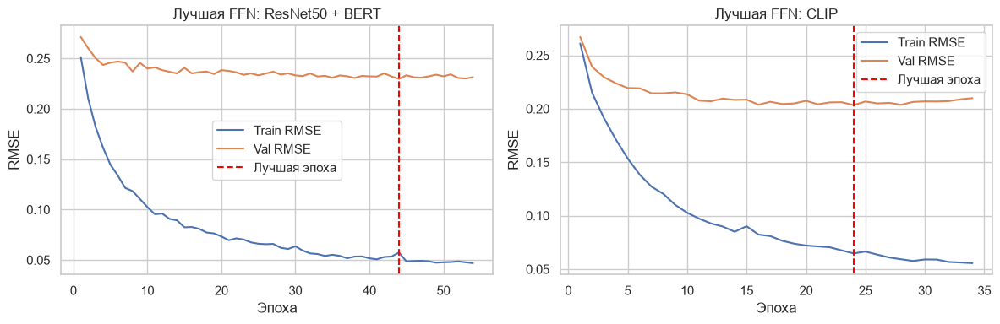

In [111]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for ax, pipeline, title in zip(
    axes, [best_resnet_ffn, best_clip_ffn], ['ResNet50 + BERT', 'CLIP']
):
    regressor = pipeline.named_steps['model']
    history = regressor.history_
    epochs = np.arange(1, len(history['val_rmse']) + 1)
    ax.plot(epochs, history['train_rmse'], label='Train RMSE')
    ax.plot(epochs, history['val_rmse'], label='Val RMSE')
    ax.axvline(regressor.best_epoch_, color='red', linestyle='--', label='Лучшая эпоха')
    ax.set(title=f'Лучшая FFN: {title}', xlabel='Эпоха', ylabel='RMSE')
    ax.legend()
plt.tight_layout()
plt.show()

**Вывод по кривым обучения.**

Train RMSE продолжает снижаться, когда Val RMSE уже почти не улучшается. Это признак переобучения. Ранняя остановка прекращает обучение после десяти эпох без улучшения, затем восстанавливает веса лучшей эпохи.

## 7.7. Выбор лучшей модели

Сравним три подхода по Val RMSE на одинаковых экспертных парах. После выбора фиксируем модель и её параметры. Внешний test до этого не используем для оценки.

In [112]:
comparison = pd.DataFrame([
    {'model': 'LinearRegression', 'val_rmse': linear_rmse},
    {'model': 'FFN (ResNet50 + BERT)', 
     'val_rmse': resnet_results.iloc[0]['val_rmse']},
    {'model': 'FFN (CLIP)', 'val_rmse': clip_results.iloc[0]['val_rmse']}
]).sort_values('val_rmse').reset_index(drop=True)
comparison

,model,val_rmse
0,FFN (CLIP),0.2034
1,FFN (ResNet50 + BERT),0.2296
2,LinearRegression,0.3545


Наименьшую ошибку на валидации получила FFN на признаках CLIP. Выберем её для разбора ошибок и финальной демонстрации поиска.

In [113]:
best_model = best_clip_ffn

Посмотрим на ошибки выбранной модели на валидации. Они помогают понять ограничения; после этого параметры модели не меняем.

In [114]:
val_prediction = best_model.predict(X_val_clip)

Сравним прогнозы выбранной модели с экспертными оценками. Чем ближе точка к диагонали, тем меньше ошибка для соответствующей пары.

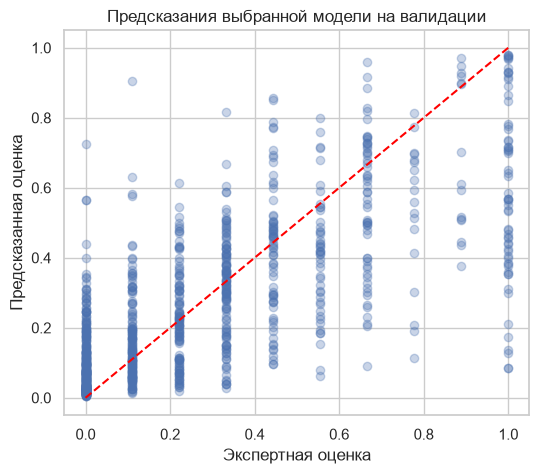

In [115]:
plt.figure(figsize=(6, 5))
plt.scatter(y_val, val_prediction, alpha=.3)
plt.plot([0, 1], [0, 1], '--', color='red')
plt.xlabel('Экспертная оценка')
plt.ylabel('Предсказанная оценка')
plt.title('Предсказания выбранной модели на валидации')
plt.show()

Прогнозы в целом растут вместе с экспертной оценкой, но разброс остаётся заметным. Есть как завышенные оценки для несоответствующих пар, так и слишком низкие прогнозы для подходящих описаний.

Найдём пары с наибольшей абсолютной ошибкой и посмотрим их фотографии. Это поможет понять, в каких случаях модель ошибается сильнее всего.

In [116]:
validation_predictions = (val_part[['image', 'query_id', 'query_text']]
    .reset_index(drop=True))
validation_predictions['target'] = y_val
validation_predictions['prediction'] = val_prediction
validation_predictions['abs_error'] = np.abs(y_val - val_prediction)
validation_predictions.sort_values('abs_error', ascending=False).head()

,image,query_id,query_text,target,prediction,abs_error
308,2086513494_dbbcb583e7.jpg,3506560025_8d0f4f9ac4.jpg#2,A woman holding a camera .,1.0000,0.0838,0.9162
89,115684808_cb01227802.jpg,115684808_cb01227802.jpg#2,Three people and a sled .,1.0000,0.0844,0.9156
122,2083434441_a93bc6306b.jpg,2083434441_a93bc6306b.jpg#2,An older woman with blond hair rides a bicycle...,1.0000,0.1291,0.8709
314,1472230829_803818a383.jpg,1472230829_803818a383.jpg#2,Rafting boat on river .,1.0000,0.1371,0.8629
880,3613955682_3860e116cf.jpg,3613955682_3860e116cf.jpg#2,A soccer team wearing red posing together .,1.0000,0.1732,0.8268


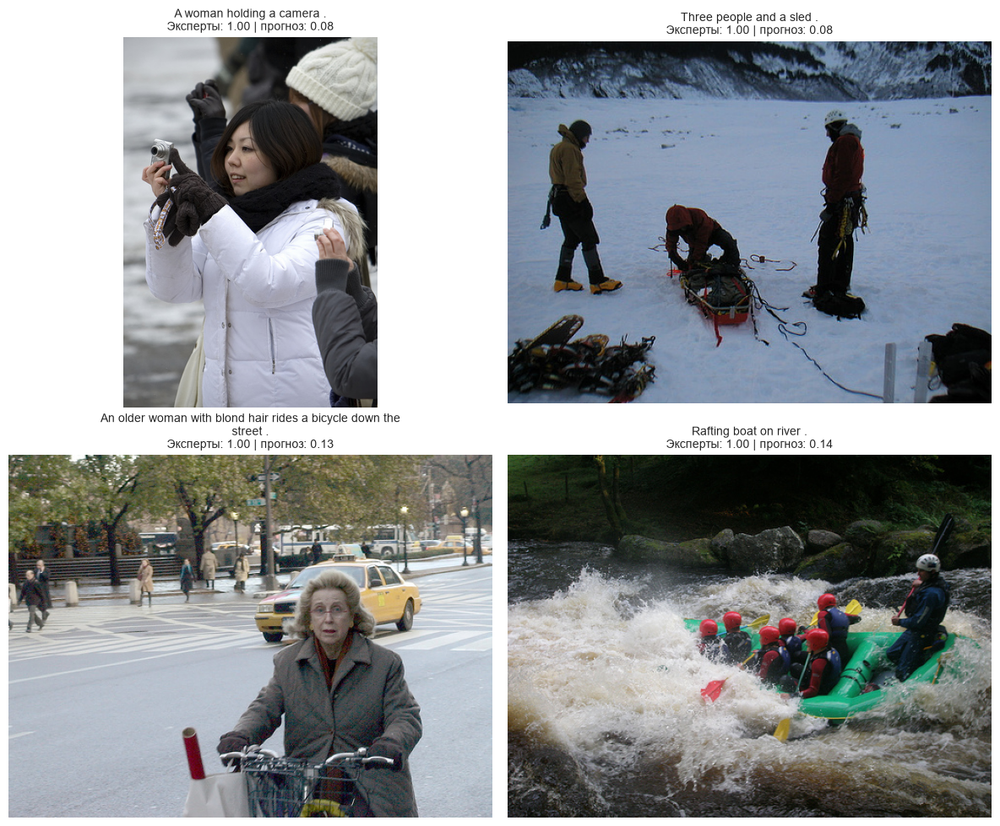

In [117]:
fig, axes = plt.subplots(2, 2, figsize=(12, 10))
for ax, row in zip(axes.flat, validation_predictions.nlargest(4, 'abs_error').itertuples()):
    with Image.open(TRAIN_IMAGES_DIR / row.image) as image:
        ax.imshow(image)
    ax.set_title(fill(row.query_text, 55) +
                 f'\nЭксперты: {row.target:.2f} | прогноз: {row.prediction:.2f}', fontsize=10)
    ax.axis('off')
plt.tight_layout()
plt.show()

**Вывод по обучению и выбору модели.**

На одинаковой валидации лучшие результаты получили:

| Модель | Val RMSE |
| :--- | ---: |
| FFN на признаках CLIP | 0.2034 |
| FFN на ResNet50 + BERT | 0.2296 |
| LinearRegression | 0.3545 |

Для внешнего тестирования выбрана FFN на признаках CLIP. Её кодировщики заморожены, а полносвязная часть и масштабировщик обучены только на train. Val RMSE использовалась для выбора параметров, поэтому не считаем её независимой финальной оценкой качества.

Разбор ошибок показывает существенные ограничения: подходящие описания фотографии с камерой, санями, велосипедом и рафтингом получили слишком низкие прогнозы. Общая RMSE не описывает каждую пару и не гарантирует, что нужная фотография получит максимальный балл среди всех кандидатов.

# 8. Тестирование выбранной модели

Проверим работу выбранной модели на внешних test_images и test_queries. В этом наборе есть описание и исходная фотография, но нет экспертной оценки. Поэтому здесь выполняем предусмотренную ТЗ визуальную демонстрацию поиска. Остальные модели на внешнем тесте не сравниваем и параметры после теста не меняем.

Векторизуем все 100 тестовых фотографий, затем исключим из выдачи фотографии, у которых хотя бы одно описание срабатывает на словарь. Запрос кодируется, объединяется с векторами кандидатов и передаётся выбранному пайплайну.

In [118]:
blocked_test_mask = test_queries_df['query_text'].str.contains(BLOCK_PATTERN, 
                                                               case=False, 
                                                               regex=True)
blocked_test_images = set(test_queries_df.loc[blocked_test_mask, 'image'])

In [119]:
all_test_names = test_images_df['image'].tolist()

In [120]:
all_test_vectors = extract_clip_images(all_test_names, TEST_IMAGES_DIR)

  0%|          | 0/4 [00:00<?, ?it/s]

In [121]:
all_test_vectors.shape

(100, 512)

Оставим в галерее разрешённые фотографии. Одинаковую маску применим к именам и векторам, чтобы сохранить их соответствие.

In [122]:
allowed_mask = ~test_images_df['image'].isin(blocked_test_images)
search_names = test_images_df.loc[allowed_mask, 'image'].tolist()
search_vectors = all_test_vectors[allowed_mask.to_numpy()]

Фотографий в разрешённой галерее:

In [123]:
len(search_names)

56

Для одного запроса создадим пары со всеми фотографиями галереи. Вектор описания повторим для каждого кандидата и объединим с признаками фотографии.

In [124]:
def pair_features(image_features, text_vector):
    return np.concatenate([image_features, np.repeat(
        text_vector.reshape(1, -1), len(image_features), axis=0)], axis=1)

In [125]:
DISCLAIMER = 'This image is unavailable in your country in compliance with local laws.'

Соберём функцию поиска: проверим запрос, получим его вектор и оценим все пары с фотографиями галереи. Вернём фотографию с максимальным прогнозом модели.

In [126]:
def find_image(query):
    if re.search(BLOCK_PATTERN, query, flags=re.IGNORECASE):
        print(DISCLAIMER)
        return None
    text_vector = extract_clip_texts([query])[0]
    features = pair_features(search_vectors, text_vector)
    predictions = best_model.predict(features)
    index = predictions.argmax()
    name = search_names[index]
    with Image.open(TEST_IMAGES_DIR / name) as image:
        result = image.convert('RGB')
    return result, name, float(predictions[index])

Проверим, что для ограниченного запроса выводится дисклеймер.

In [127]:
find_image('A little child is playing with a ball.')

This image is unavailable in your country in compliance with local laws.


Выберем десять запросов из исходного тестового файла. Для ограниченных запросов выводим дисклеймер. Для остальных покажем найденную и исходную фотографии.

In [128]:
demo_queries = test_queries_df.sample(10, random_state=RANDOM_STATE)

A group of girls who are gothically dressed standing together
This image is unavailable in your country in compliance with local laws.
A woman and girl riding downhill on a sled with a dog running alongside them
This image is unavailable in your country in compliance with local laws.
The dog is running .


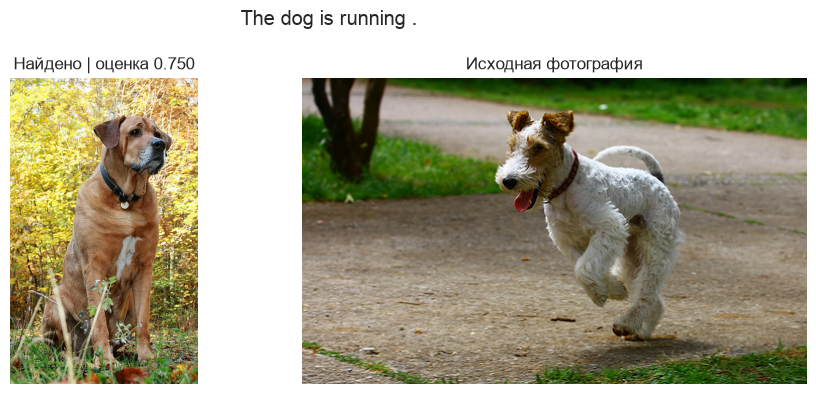

A group of people are ice skating in a big city .


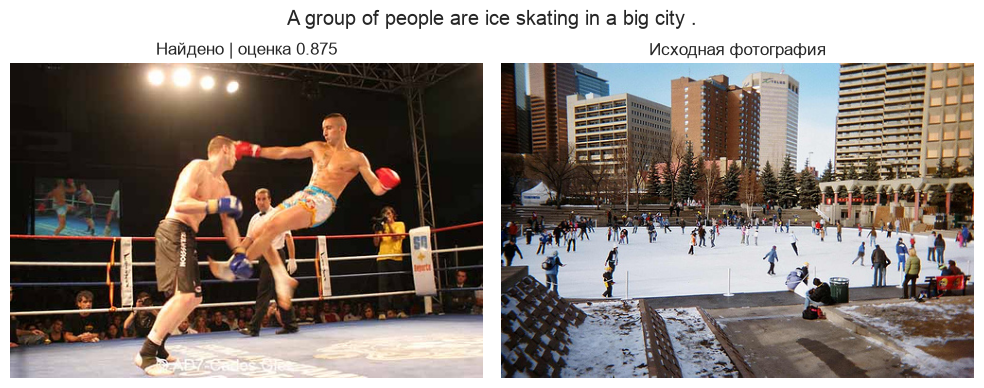

Little kid in blue coat and hat riding a tricycle .
This image is unavailable in your country in compliance with local laws.
Two black dogs fighting over an orange toy .


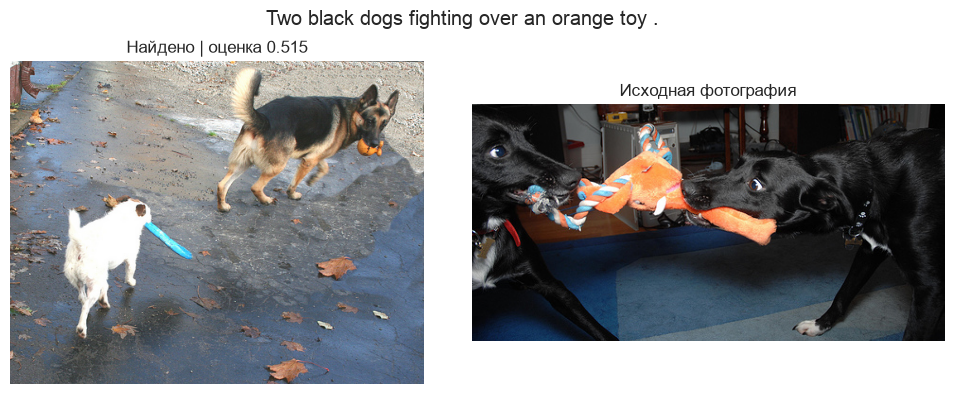

A dog jumping for a tennis ball near an ocean


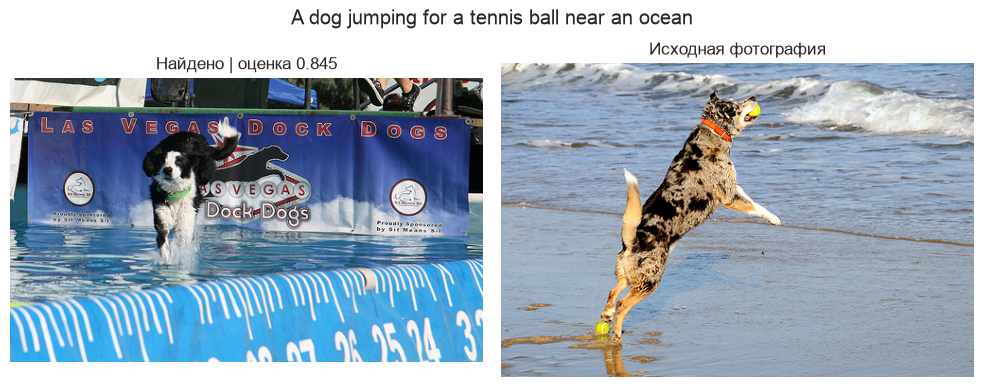

Boy flying a distant kite .
This image is unavailable in your country in compliance with local laws.
kids play ultimate Frisbee .
This image is unavailable in your country in compliance with local laws.
A girl in a purple shirt feeding ducks
This image is unavailable in your country in compliance with local laws.


In [129]:
for row in demo_queries.itertuples():
    print(row.query_text)
    result = find_image(row.query_text)
    if result is None:
        continue
    image, name, score = result
    fig, axes = plt.subplots(1, 2, figsize=(10, 4))
    axes[0].imshow(image)
    axes[0].set_title(f'Найдено | оценка {score:.3f}')
    if row.image in search_names:
        with Image.open(TEST_IMAGES_DIR / row.image) as expected:
            axes[1].imshow(expected)
        axes[1].set_title('Исходная фотография')
    else:
        axes[1].text(.5, .5, fill(DISCLAIMER, 30), ha='center', va='center')
    for ax in axes:
        ax.axis('off')
    fig.suptitle(fill(row.query_text, 85))
    plt.tight_layout()
    plt.show()

**Вывод по внешнему тестированию.**

Векторизованы все 100 тестовых фотографий. После фильтрации 44 фотографий, связанных с ограниченными описаниями, в разрешённой галерее осталось 56. Из исходного test_queries выбраны десять случайных запросов: шесть вызвали дисклеймер, для четырёх показаны найденная и исходная фотографии.

Выдача соответствует описанию лишь частично. Для бегущей собаки найдена сидящая; для двух чёрных собак с оранжевой игрушкой найдены собаки другого окраса; для прыжка за мячом у океана - собака у бассейна. Запрос о катании на коньках привёл к фотографии единоборства, хотя предсказанная оценка составила около 0,88. Это показывает, что высокий балл модели может сопровождать ошибочную выдачу.

У внешних запросов нет экспертного таргета, поэтому RMSE для этого набора не рассчитывается. Тестирование здесь состоит из визуальной проверки выбранной модели, как описано в ТЗ. После просмотра теста параметры не менялись.

# 9. Выводы

<div style='border:solid steelblue 2px; padding: 20px'>

<div style='font-size: 20px; font-weight: bold; margin-bottom: 10px; color: steelblue;'>Итоговый вывод по проекту</div>

**Задача**: Построить модель, которая получает векторы фотографии и текстового описания и предсказывает степень их соответствия в диапазоне от 0 до 1 на основе экспертных оценок.

**Цель**: Оценить, насколько практически осуществим сервис поиска фотографий по текстовому описанию, и подготовить его демонстрационную версию для фотохостинга With Sense.

**Исходные данные и предобработка**: Исходная обучающая выборка содержала 5822 пары 'изображение - описание'. Для каждой пары были доступны оценки трёх экспертов. Также исследованы краудсорсинговые оценки и отдельные тестовые фотографии с запросами.

**Подготовка данных включала:**

1. Проверку пропусков, дубликатов и объединение таблиц по паре `image` и `query_id`.
2. Усреднение трёх экспертных оценок и перевод шкалы от 1 до 4 в диапазон от 0 до 1 по формуле `(mean - 1) / 3`.
3. Сравнение экспертной и краудсорсинговой разметки. На общих парах корреляция составила 0,791, средние оценки - 0,40 и 0,20, среднее абсолютное расхождение - 0,226. Для обучения выбран экспертный таргет.
4. Фильтрацию ограниченного контента по словарю: исключались соответствующие описания и связанные с ними фотографии. После фильтрации осталось **3162 пары, 703 фотографии и 665 описаний**.
5. Разделение по фотографиям на train и val в пропорции около 70/30. В train вошли **2221 пара и 492 фотографии**, в val - **941 пара и 211 фотографий**. Общих фотографий между выборками нет. Масштабировщики обучались только на train.

**Векторизация и поиск лучшей модели**: Рассмотрены два набора признаков: ResNet50 + BERT с размерностью объединённого вектора **2816** и CLIP с размерностью **1024**. Предобученные кодировщики использовались без дообучения. На полученных признаках обучены линейная регрессия и полносвязные сети.

Для каждой семьи FFN проверены **24 конфигурации** с разными архитектурами, Dropout, BatchNorm, learning rate, batch size и weight decay. Для ограничения переобучения использована ранняя остановка с восстановлением весов лучшей эпохи.

**Сравнение моделей:**

| Модель | Признаки | Val RMSE |
|---|---|---:|
| LinearRegression | ResNet50 + BERT | 0,3545 |
| FFN | ResNet50 + BERT | 0,2296 |
| **FFN** | **CLIP** | **0,2034** |

Модели сравнивались на одинаковых валидационных парах по **RMSE**. Метрика характеризует ошибку прогноза экспертной оценки и сильнее штрафует большие отклонения. RMSE не является процентом точности поиска и не показывает долю запросов, для которых найдена подходящая фотография. Валидация использовалась при подборе параметров, поэтому её результат не является независимой итоговой оценкой качества.

**Лучшая модель по Val RMSE - FFN на признаках CLIP.** Её архитектура: **1024 -> 128 -> 64 -> 1**, два скрытых слоя с ReLU и Dropout 0,3, без BatchNorm. На выходе используется Sigmoid. Лучшие параметры: `learning rate = 0.001`, `batch size = 128`, `weight decay = 0.001`; лучшие веса получены на **24-й эпохе**.

CLIP здесь формирует векторы изображения и текста, а обученная FFN предсказывает нормализованную экспертную оценку. Именно эта модель выбрана для внешнего тестирования.

**Тестирование и качество поиска**: Получены векторы всех **100 тестовых фотографий**. После фильтрации 44 фотографий в разрешённой галерее осталось **56**. Для демонстрации случайно выбраны **10 запросов** из исходного `test_queries`: шесть вызвали дисклеймер, для четырёх показаны найденная и исходная фотографии.

Функция поиска векторизует запрос, оценивает его соответствие каждой разрешённой фотографии и возвращает фотографию с максимальным прогнозом. Для ограниченного запроса выводится предусмотренный ТЗ дисклеймер.

**Внешняя проверка показала существенные ошибки:**

- Для запроса о бегущей собаке найдена сидящая собака.
- Для двух чёрных собак с оранжевой игрушкой найдены собаки другого окраса.
- Для прыжка за мячом у океана найдена собака у бассейна.
- Для запроса о катании на коньках найдена фотография единоборства с оценкой около **0,88**.

Таким образом, модель иногда улавливает общий объект, но ошибается в действиях, деталях и даже сцене целиком. Высокий прогноз не гарантирует подходящую выдачу. У внешних запросов нет экспертных оценок, поэтому RMSE для них не рассчитывалась: качество проверено визуально, как предусмотрено ТЗ. После просмотра внешнего теста параметры не менялись.

**Насколько практически осуществим такой сервис?**

**Технически создать такой сервис возможно.** В проекте реализован полный процесс: обработка запроса, получение векторов текста и изображений, прогноз соответствия и выбор фотографии. Предобученные кодировщики позволяют построить такой прототип без обучения больших нейросетей с нуля.

**Однако качество текущей модели недостаточно для полноценного поискового сервиса.** Уже в галерее из 56 фотографий встречаются заметные ошибки. Полученные результаты подтверждают работоспособность технического процесса, но пока не подтверждают, что пользователь будет регулярно получать подходящие фотографии. Проверка на такой небольшой галерее также не позволяет оценить качество и скорость поиска на большом архиве.

Неудачные выдачи показывают ограничения проверенного решения. По ним нельзя сделать вывод, что задача поиска фотографий по тексту в принципе нерешаема. Для практического применения необходимо улучшить сопоставление изображения с запросом и отдельно проверить результат на более разнообразных сценах и галерее большего размера.

**Польза для фотографов и решение для бизнеса**: Поиск по описанию сцены может помочь профессиональным фотографам подбирать референсы для будущих съёмок без ручного просмотра всего архива. Для With Sense это потенциальная дополнительная функция, которая использует уже размещённые фотографии и их описания. Экономия времени пользователей и финансовый эффект в проекте не измерялись.

Текущие ошибки снижают эту пользу: фотографу приходится отсеивать снимки с неподходящим действием, окружением или составом объектов. Поэтому улучшение RMSE само по себе ещё не подтверждает достижение бизнес-цели - помочь пользователю найти подходящий референс.

**Рекомендация для With Sense**: Продолжить доработку на уровне PoC. Перед полноценным запуском необходимо улучшить выдачу и проверить с фотографами, помогает ли поиск решать их реальные задачи и сокращает ли время подбора референсов по сравнению с привычным способом. На текущих результатах обещать такой эффект нельзя.

**Что стоит проверить в следующих экспериментах:**

1. Увеличить количество и разнообразие размеченных пар. Добавить сложные отрицательные примеры: фотографии с похожими объектами, но другим действием, цветом или окружением.
2. Рассмотреть дообучение кодировщиков как отдельный эксперимент. В текущей работе оно не проводилось, поэтому его пользу ещё предстоит проверить.
3. Проверить качество поиска и время ответа на более широком наборе запросов и фотографий. Снижения RMSE по отдельным парам недостаточно для вывода о полезности сервиса.
4. Для практического использования улучшить проверку ограниченного контента: словарный фильтр зависит от полноты описаний и сам по себе не определяет содержимое фотографии.

<span style='color: #1565c0; font-weight: bold;'>Главный итог: техническая реализация поиска фотографий по текстовому описанию осуществима. В проекте построен работающий прототип; лучшая Val RMSE - 0,2034 у FFN на признаках CLIP. Для полноценного сервиса текущего качества недостаточно: необходимо улучшить поисковую выдачу и подтвердить её полезность на более широком наборе запросов и фотографий.</span>

</div>
